# RQ1 — How does evidence definition reshape the apparent learnability of phage lytic function?

## Scientific question

**How much does predictive behavior change when the biological positive class is kept conceptually fixed but the comparison/background class changes?**

This notebook focuses on the three global supervised task formulations:

- `global_easy`
- `global_hard`
- `global_mixed`

The aim is not to declare one task intrinsically “easier” or “harder”. Instead, we ask whether changing the definition of the background changes:

1. apparent predictive performance;
2. prevalence-adjusted performance;
3. sensitivity to `R` and `S`;
4. representation and algorithm rankings;
5. the magnitude of the task-definition effect relative to representation/algorithm effects;
6. conclusions when evaluation is restricted to shared test entities.

> **Scope rule:** binary-vs-multiclass formulation and `PU conservative` vs `PU broad` are deliberately left for their dedicated RQs. This notebook isolates supervised negative/background definition.

## Interpretation contract

Native outer-test sets can differ between `global_easy`, `global_hard`, and `global_mixed`. Therefore:

- matched-factor task contrasts are factorial native-test contrasts, not automatically entity-level paired;
- AP must always be interpreted together with test prevalence / AP baseline;
- the strongest claims should be checked again using shared outer-test entities where possible;
- `easy` and `hard` are computational task IDs, not conclusions about empirical difficulty.

A result becomes especially interesting for the *Briefings* framing if task definition changes not only the absolute metric, but also the shape of the `R×S` response, model ranking, or robustness.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    matthews_corrcoef,
    average_precision_score,
    balanced_accuracy_score,
)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 200)

warnings.filterwarnings("ignore", category=FutureWarning)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]
GLOBAL_TASKS = ["global_easy", "global_hard", "global_mixed"]

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/stage12b").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing results/analysis_supervised/stage12a and stage12b."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
STAGE12B = ROOT / "results/analysis_supervised/stage12b"

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

expected = pd.read_csv(
    STAGE12A / "expected_experiment_registry.tsv",
    sep="\t",
    low_memory=False,
)

negative = pd.read_csv(
    STAGE12B / "negative_definition_contrasts.tsv",
    sep="\t",
    low_memory=False,
)

rep_deltas = pd.read_csv(
    STAGE12B / "representation_pairwise_deltas.tsv",
    sep="\t",
    low_memory=False,
)

alg_deltas = pd.read_csv(
    STAGE12B / "algorithm_pairwise_deltas.tsv",
    sep="\t",
    low_memory=False,
)

global_df = master[master["task"].isin(GLOBAL_TASKS)].copy()

print("Total supervised families:", len(master))
print("Global-task families:", len(global_df))
print("Expected global families:", 3 * 16 * global_df["representation"].nunique() * global_df["algorithm"].nunique())
print("Representations:", sorted(global_df["representation"].unique()))
print("Algorithms:", sorted(global_df["algorithm"].unique()))
print("R:", sorted(global_df["R"].unique(), reverse=True))
print("S:", sorted(global_df["S"].unique(), reverse=True))

coverage = (
    global_df.groupby(["task", "representation", "algorithm"])
    .size()
    .rename("n_RxS_cells")
    .reset_index()
)

display(coverage["n_RxS_cells"].value_counts().sort_index().to_frame("n_groups"))
assert coverage["n_RxS_cells"].eq(16).all(), "At least one global task × representation × algorithm group is missing R×S cells."

Total supervised families: 2240
Global-task families: 960
Expected global families: 960
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']
R: [np.int64(90), np.int64(70), np.int64(50), np.int64(30)]
S: [np.int64(90), np.int64(70), np.int64(50), np.int64(30)]


,n_groups
n_RxS_cells,
16,60


## 1. What is the apparent difficulty of each task?

In [3]:
metric_candidates = [
    "mcc",
    "ap",
    "ap_gain",
    "roc_auc",
    "balanced_accuracy",
    "f1",
    "precision",
    "recall",
    "specificity",
]

metrics = [m for m in metric_candidates if m in global_df.columns]
print("Available metrics:", metrics)

prevalence_candidates = [
    "test_prevalence",
    "prevalence",
    "positive_prevalence",
    "class_prevalence",
]
prevalence_col = next((c for c in prevalence_candidates if c in global_df.columns), None)
print("Prevalence column:", prevalence_col)

summary_aggs = {}
for metric in metrics:
    summary_aggs[f"{metric}_mean"] = (metric, "mean")
    summary_aggs[f"{metric}_median"] = (metric, "median")
    summary_aggs[f"{metric}_min"] = (metric, "min")
    summary_aggs[f"{metric}_max"] = (metric, "max")

if prevalence_col:
    summary_aggs["prevalence_mean"] = (prevalence_col, "mean")
    summary_aggs["prevalence_median"] = (prevalence_col, "median")
    summary_aggs["prevalence_min"] = (prevalence_col, "min")
    summary_aggs["prevalence_max"] = (prevalence_col, "max")

task_summary = (
    global_df.groupby("task", as_index=False)
    .agg(**summary_aggs)
)

display(task_summary)

Available metrics: ['mcc', 'ap', 'ap_gain', 'roc_auc', 'balanced_accuracy', 'f1', 'precision', 'recall', 'specificity']
Prevalence column: prevalence


,task,mcc_mean,mcc_median,mcc_min,mcc_max,ap_mean,ap_median,ap_min,ap_max,ap_gain_mean,ap_gain_median,ap_gain_min,ap_gain_max,roc_auc_mean,roc_auc_median,roc_auc_min,roc_auc_max,balanced_accuracy_mean,balanced_accuracy_median,balanced_accuracy_min,balanced_accuracy_max,f1_mean,f1_median,f1_min,f1_max,precision_mean,precision_median,precision_min,precision_max,recall_mean,recall_median,recall_min,recall_max,specificity_mean,specificity_median,specificity_min,specificity_max,prevalence_mean,prevalence_median,prevalence_min,prevalence_max
0,global_easy,0.687194,0.715267,0.111129,0.963380,0.799049,0.856390,0.417073,0.987657,0.632528,0.685801,0.257098,0.834170,0.919413,0.944791,0.731163,0.996104,0.828831,0.843680,0.507402,0.977461,0.720383,0.758356,0.029178,0.968816,0.805046,0.851323,0.414039,1.000000,0.697736,0.751068,0.014805,0.961678,0.959926,0.975477,0.786112,1.000000,0.166521,0.162461,0.153258,0.184308
1,global_hard,0.869307,0.896734,0.666141,0.964477,0.989592,0.992753,0.946507,0.998760,0.296692,0.292053,0.251334,0.341841,0.978062,0.985101,0.905806,0.996471,0.939290,0.950456,0.847550,0.986121,0.956894,0.965589,0.851508,0.989906,0.969046,0.974114,0.902299,0.995101,0.945890,0.960334,0.756250,0.990997,0.932690,0.944494,0.783094,0.987952,0.692900,0.691797,0.653479,0.733400
2,global_mixed,0.682930,0.721355,0.098878,0.963493,0.791112,0.846885,0.399900,0.987336,0.640148,0.694360,0.262514,0.840655,0.917833,0.941827,0.738963,0.996167,0.826890,0.850346,0.505612,0.976285,0.712198,0.749322,0.022198,0.968728,0.799054,0.849865,0.362841,1.000000,0.692365,0.751731,0.011223,0.962859,0.961414,0.979513,0.782603,1.000000,0.150964,0.149552,0.130149,0.165085


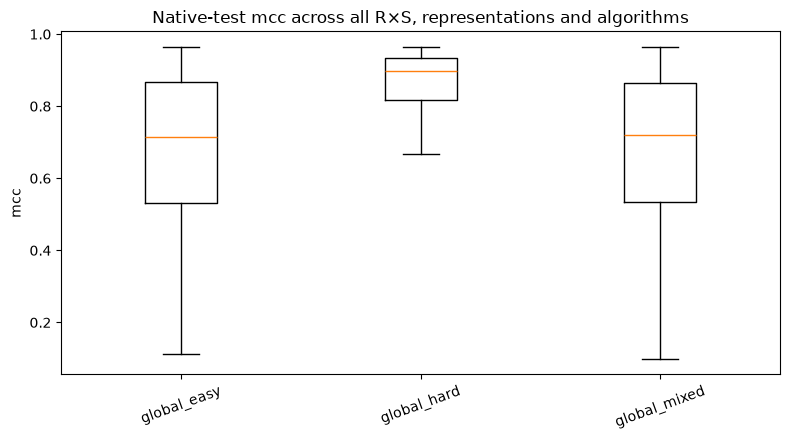

In [4]:
PRIMARY = "mcc" if "mcc" in global_df.columns else metrics[0]

fig, ax = plt.subplots(figsize=(8, 4.5))
data = [
    global_df.loc[global_df["task"].eq(task), PRIMARY].dropna().to_numpy()
    for task in GLOBAL_TASKS
]
ax.boxplot(data, tick_labels=GLOBAL_TASKS, showfliers=False)
ax.set_ylabel(PRIMARY)
ax.set_title(f"Native-test {PRIMARY} across all R×S, representations and algorithms")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Why AP must be contextualized

If prevalence differs substantially across the three task definitions, raw AP is not directly comparable as a measure of increment over baseline. Therefore inspect:

- raw AP;
- prevalence / AP baseline;
- `ap_gain` when available.

ap                               prevalence                                 ap_gain                              
                  mean    median       min       max       mean    median       min       max      mean    median       min       max
task                                                                                                                                 
global_easy   0.799049  0.856390  0.417073  0.987657   0.166521  0.162461  0.153258  0.184308  0.632528  0.685801  0.257098  0.834170
global_hard   0.989592  0.992753  0.946507  0.998760   0.692900  0.691797  0.653479  0.733400  0.296692  0.292053  0.251334  0.341841
global_mixed  0.791112  0.846885  0.399900  0.987336   0.150964  0.149552  0.130149  0.165085  0.640148  0.694360  0.262514  0.840655

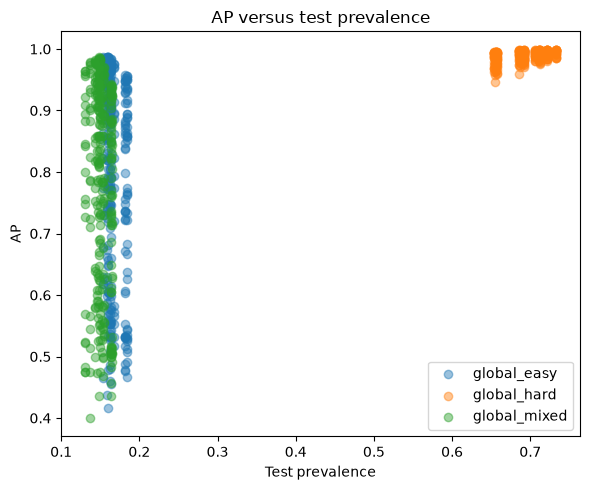

In [6]:
if "ap" in global_df.columns:
    numeric_cols = ["ap"]

    if prevalence_col:
        numeric_cols.append(prevalence_col)

    if "ap_gain" in global_df.columns:
        numeric_cols.append("ap_gain")

    display(
        global_df[
            ["task"] + numeric_cols
        ]
        .groupby("task")[numeric_cols]
        .agg(["mean", "median", "min", "max"])
    )

    if prevalence_col:
        fig, ax = plt.subplots(figsize=(6, 5))

        for task in GLOBAL_TASKS:
            g = global_df[global_df["task"].eq(task)]

            ax.scatter(
                g[prevalence_col],
                g["ap"],
                alpha=0.45,
                label=task,
            )

        ax.set_xlabel("Test prevalence")
        ax.set_ylabel("AP")
        ax.legend()
        ax.set_title("AP versus test prevalence")

        plt.tight_layout()
        plt.show()

## 2. Matched-factor task-definition contrasts across the complete R×S design

In [7]:
display(negative.head())
print("Rows:", len(negative))
print("Metrics:", sorted(negative["metric"].dropna().unique()))

contrast_cols = [
    "hard_minus_easy",
    "mixed_minus_easy",
    "hard_minus_mixed",
]

contrast_summary_rows = []

for metric in sorted(negative["metric"].unique()):
    sub = negative[negative["metric"].eq(metric)]

    for contrast in contrast_cols:
        x = sub[contrast].dropna()

        contrast_summary_rows.append(
            {
                "metric": metric,
                "contrast": contrast,
                "n": len(x),
                "mean_delta": x.mean(),
                "median_delta": x.median(),
                "q25": x.quantile(0.25),
                "q75": x.quantile(0.75),
                "min": x.min(),
                "max": x.max(),
                "fraction_positive": (x > 0).mean(),
                "fraction_negative": (x < 0).mean(),
            }
        )

contrast_summary = pd.DataFrame(contrast_summary_rows)
display(contrast_summary)

,R,S,representation,algorithm,metric,global_easy,global_hard,global_mixed,hard_minus_easy,mixed_minus_easy,hard_minus_mixed,comparison_note
0,30,30,esm2_t30_150m,KNN,mcc,0.887662,0.904025,0.873647,0.016363,-0.014015,0.030378,Matched-factor native-test contrast; not entit...
1,30,30,esm2_t30_150m,LR,mcc,0.840543,0.885758,0.818758,0.045215,-0.021785,0.067000,Matched-factor native-test contrast; not entit...
2,30,30,esm2_t30_150m,MLP,mcc,0.877293,0.900689,0.881569,0.023396,0.004276,0.019120,Matched-factor native-test contrast; not entit...
3,30,30,esm2_t30_150m,RF,mcc,0.831723,0.915296,0.805241,0.083572,-0.026483,0.110055,Matched-factor native-test contrast; not entit...
4,30,30,esm2_t30_150m,XGB,mcc,0.879389,0.900904,0.867012,0.021516,-0.012377,0.033892,Matched-factor native-test contrast; not entit...


Rows: 960
Metrics: ['ap', 'ap_gain', 'mcc']


,metric,contrast,n,mean_delta,median_delta,q25,q75,min,max,fraction_positive,fraction_negative
0,ap,hard_minus_easy,320,0.190543,0.136168,0.048731,0.326607,0.008713,0.563603,1.000000,0.000000
1,ap,mixed_minus_easy,320,-0.007938,-0.005953,-0.018318,0.003144,-0.095530,0.087428,0.296875,0.703125
2,ap,hard_minus_mixed,320,0.198481,0.144119,0.058031,0.344724,0.009034,0.580776,1.000000,0.000000
3,ap_gain,hard_minus_easy,320,-0.335836,-0.375947,-0.485048,-0.198800,-0.555901,0.032497,0.018750,0.981250
4,ap_gain,mixed_minus_easy,320,0.007620,0.007465,-0.002155,0.018103,-0.079272,0.099923,0.706250,0.293750
5,ap_gain,hard_minus_mixed,320,-0.343456,-0.387181,-0.490457,-0.212442,-0.568826,0.041765,0.006250,0.993750
6,mcc,hard_minus_easy,320,0.182114,0.169034,0.069009,0.267721,-0.014703,0.635155,0.965625,0.034375
7,mcc,mixed_minus_easy,320,-0.004264,-0.004137,-0.017381,0.007458,-0.057394,0.065651,0.409375,0.590625
8,mcc,hard_minus_mixed,320,0.186378,0.167108,0.071243,0.265516,-0.013447,0.633272,0.971875,0.028125


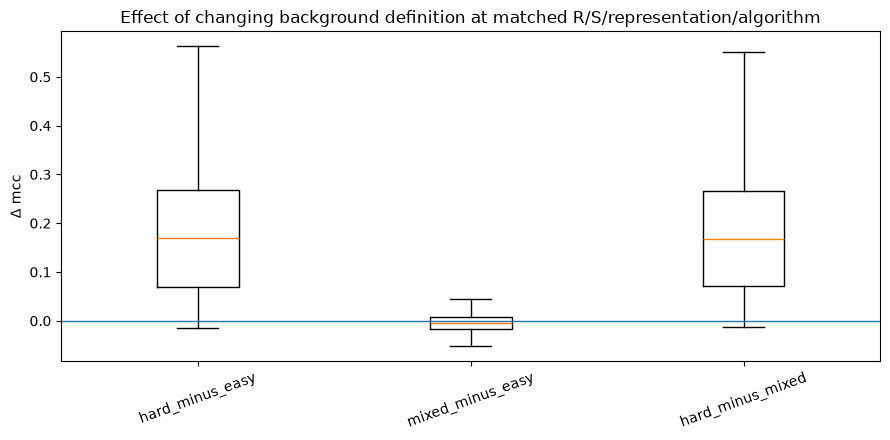

In [8]:
metric_to_plot = "mcc" if "mcc" in negative["metric"].unique() else negative["metric"].iloc[0]
sub = negative[negative["metric"].eq(metric_to_plot)]

fig, ax = plt.subplots(figsize=(9, 4.5))
data = [sub[c].dropna().to_numpy() for c in contrast_cols]
ax.boxplot(data, tick_labels=contrast_cols, showfliers=False)
ax.axhline(0, linewidth=1)
ax.set_ylabel(f"Δ {metric_to_plot}")
ax.set_title("Effect of changing background definition at matched R/S/representation/algorithm")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 3. Does the task-definition effect depend on representation?

A strong *Briefings* result would be that the effect of changing the background is not constant across protein representations.

hard_minus_easy                                         mixed_minus_easy                                         hard_minus_mixed                                \
                          mean    median       std       min       max             mean    median       std       min       max             mean    median       std       min   
representation                                                                                                                                                                   
esm2_t30_150m         0.025385  0.018271  0.026884 -0.014703  0.114060        -0.006049 -0.005327  0.010609 -0.026815  0.013625         0.031434  0.026221  0.029617 -0.013447   
esm2_t6_8m            0.131635  0.127711  0.051935  0.037379  0.235723        -0.005432 -0.005772  0.019897 -0.051342  0.045528         0.137067  0.129144  0.058634  0.043603   
onehot_1024           0.345895  0.329903  0.120950  0.113698  0.635155        -0.007741 -0.007026  0.022477 -0.057394  0.037154         0.353636  0.334546  0.125280  0.097079   
roxy_48               0.225540  0.205416  0.075818  0.114190  0.385081         0.002167  0.002074  0.021572 -0.038280  0.065651         0.223374  0.204600  0.081122  0.108285   

                          
                     max  
representation            
esm2_t30_150m   0.110055  
esm2_t6_8m      0.262686  
onehot_1024     0.633272  
roxy_48         0.403918

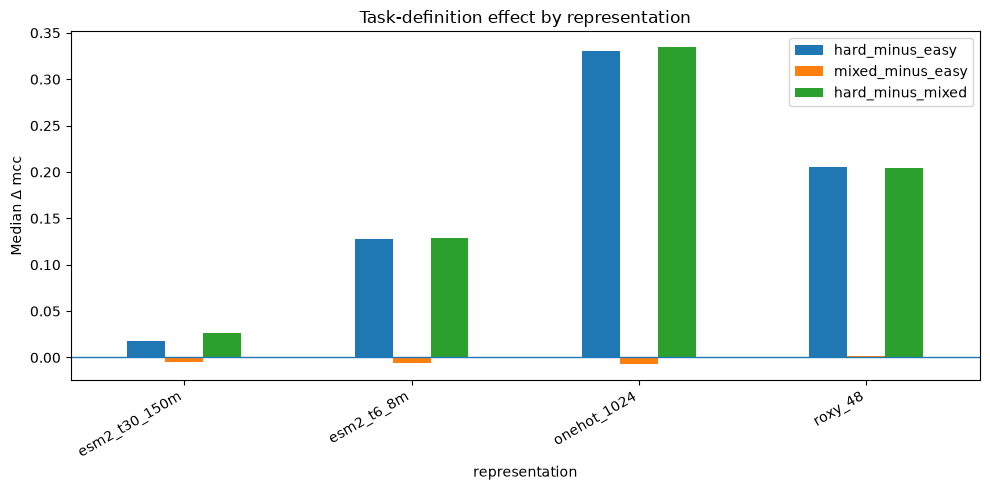

In [9]:
rep_effect = (
    negative[negative["metric"].eq(metric_to_plot)]
    .groupby("representation")[contrast_cols]
    .agg(["mean", "median", "std", "min", "max"])
)

display(rep_effect)

plot_df = (
    negative[negative["metric"].eq(metric_to_plot)]
    .groupby("representation", as_index=False)[contrast_cols]
    .median()
    .set_index("representation")
)

plot_df.plot(kind="bar", figsize=(10, 5))
plt.axhline(0, linewidth=1)
plt.ylabel(f"Median Δ {metric_to_plot}")
plt.title("Task-definition effect by representation")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 4. Does the task-definition effect depend on the downstream learner?

hard_minus_easy                                         mixed_minus_easy                                         hard_minus_mixed                                \
                     mean    median       std       min       max             mean    median       std       min       max             mean    median       std       min   
algorithm                                                                                                                                                                   
KNN              0.128027  0.132843  0.094923 -0.005128  0.355229         0.001142 -0.000235  0.016539 -0.031459  0.037897         0.126885  0.133691  0.091502 -0.009805   
LR               0.232214  0.249951  0.128540  0.014611  0.396888        -0.016816 -0.017420  0.015441 -0.052101  0.022315         0.249030  0.280328  0.128862  0.024563   
MLP              0.145480  0.130763  0.118404 -0.014703  0.376472        -0.004340 -0.001361  0.020475 -0.044119  0.065651         0.149820  0.122924  0.121425 -0.013447   
RF               0.248104  0.203186  0.187312  0.015933  0.635155        -0.002629 -0.003669  0.021477 -0.057394  0.043138         0.250733  0.198842  0.191113  0.016796   
XGB              0.156743  0.130586  0.118850 -0.006114  0.409126         0.001324  0.001470  0.017654 -0.039265  0.044623         0.155419  0.133566  0.117525 -0.000288   

                     
                max  
algorithm            
KNN        0.331518  
LR         0.413542  
MLP        0.403914  
RF         0.633272  
XGB        0.395460

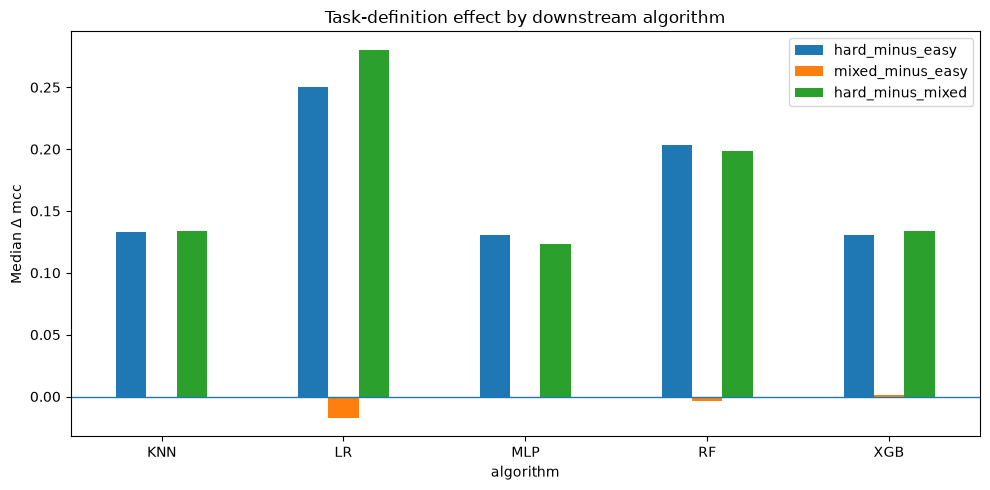

In [10]:
alg_effect = (
    negative[negative["metric"].eq(metric_to_plot)]
    .groupby("algorithm")[contrast_cols]
    .agg(["mean", "median", "std", "min", "max"])
)

display(alg_effect)

plot_df = (
    negative[negative["metric"].eq(metric_to_plot)]
    .groupby("algorithm", as_index=False)[contrast_cols]
    .median()
    .set_index("algorithm")
)

plot_df.plot(kind="bar", figsize=(10, 5))
plt.axhline(0, linewidth=1)
plt.ylabel(f"Median Δ {metric_to_plot}")
plt.title("Task-definition effect by downstream algorithm")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Task-definition effect as a function of R and S

For each contrast, calculate the median task-definition effect across representations and algorithms at every `R×S` cell.


 hard_minus_easy


S,90,70,50,30
R,,,,
90,0.123854,0.132843,0.128955,0.163232
70,0.149566,0.130757,0.174844,0.203698
50,0.192697,0.174105,0.171474,0.204787
30,0.188316,0.205239,0.205819,0.205786


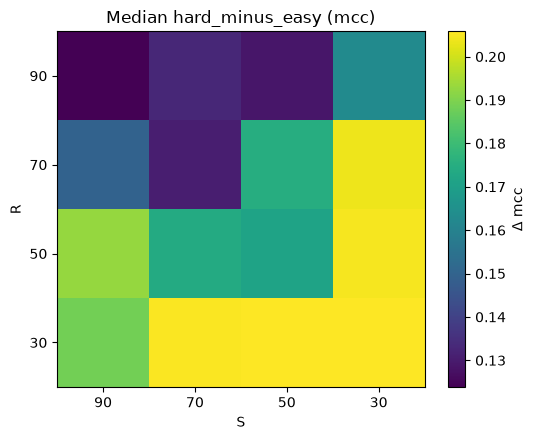


 mixed_minus_easy


S,90,70,50,30
R,,,,
90,-0.007436,0.005723,-0.006120,0.007673
70,-0.005403,-0.009777,-0.004904,-0.011925
50,0.005317,-0.010001,0.001314,-0.013157
30,0.003039,-0.002902,-0.017016,-0.011227


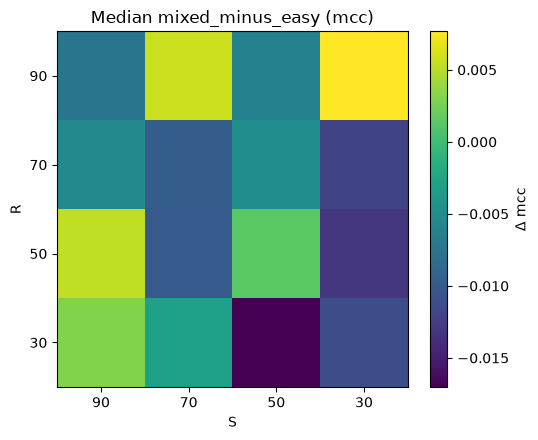


 hard_minus_mixed


S,90,70,50,30
R,,,,
90,0.125467,0.108015,0.122879,0.148652
70,0.139565,0.136263,0.182186,0.216326
50,0.174761,0.188655,0.179251,0.229364
30,0.186031,0.175400,0.215789,0.215777


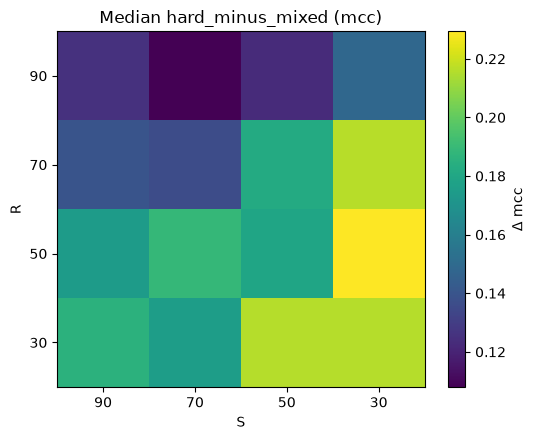

In [11]:
def effect_surface(df, contrast, metric="mcc", agg="median"):
    sub = df[df["metric"].eq(metric)].copy()
    grouped = (
        sub.groupby(["R", "S"])[contrast]
        .agg(agg)
        .reset_index()
    )
    return (
        grouped.pivot(index="R", columns="S", values=contrast)
        .reindex(index=R_LEVELS, columns=S_LEVELS)
    )

for contrast in contrast_cols:
    surface = effect_surface(negative, contrast, metric_to_plot)
    print("\n", contrast)
    display(surface)

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(surface.to_numpy(), aspect="auto")
    ax.set_xticks(range(len(S_LEVELS)), S_LEVELS)
    ax.set_yticks(range(len(R_LEVELS)), R_LEVELS)
    ax.set_xlabel("S")
    ax.set_ylabel("R")
    ax.set_title(f"Median {contrast} ({metric_to_plot})")
    plt.colorbar(im, ax=ax, label=f"Δ {metric_to_plot}")
    plt.tight_layout()
    plt.show()

## 6. R curves for each task, holding S fixed

REPRESENTATION = esm2_t30_150m
ALGORITHM      = KNN
METRIC         = mcc


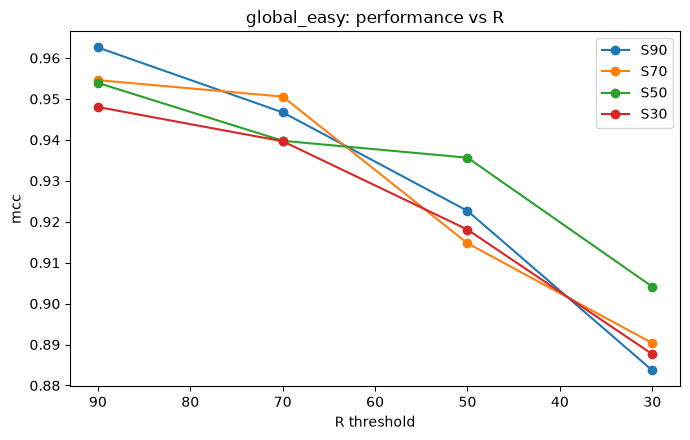

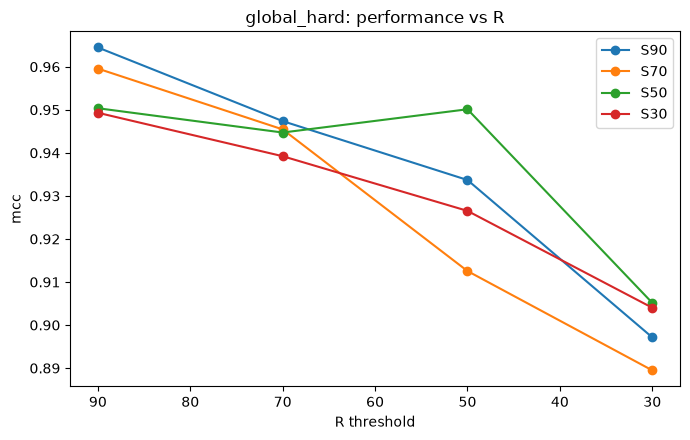

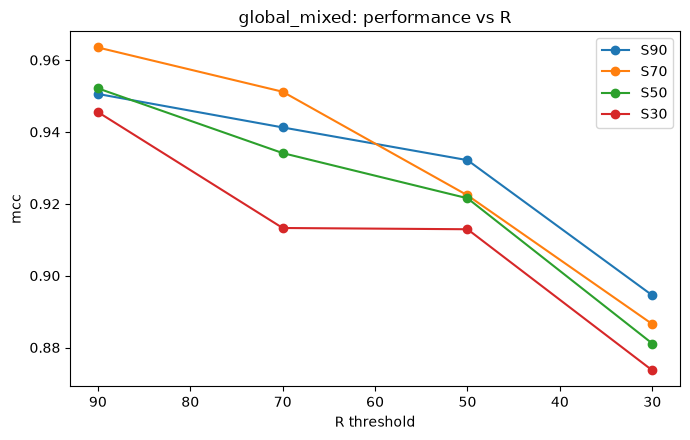

In [12]:
# Edit these parameters to inspect any model family.
REPRESENTATION = sorted(global_df["representation"].unique())[0]
ALGORITHM = sorted(global_df["algorithm"].unique())[0]
CURVE_METRIC = PRIMARY

print("REPRESENTATION =", REPRESENTATION)
print("ALGORITHM      =", ALGORITHM)
print("METRIC         =", CURVE_METRIC)

sub = global_df[
    global_df["representation"].eq(REPRESENTATION)
    & global_df["algorithm"].eq(ALGORITHM)
].copy()

for task in GLOBAL_TASKS:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    g = sub[sub["task"].eq(task)]

    for s in S_LEVELS:
        curve = (
            g[g["S"].eq(s)]
            .set_index("R")
            .reindex(R_LEVELS)
        )
        ax.plot(
            R_LEVELS,
            curve[CURVE_METRIC],
            marker="o",
            label=f"S{s}",
        )

    ax.set_xlabel("R threshold")
    ax.set_ylabel(CURVE_METRIC)
    ax.set_title(f"{task}: performance vs R")
    ax.legend()
    ax.invert_xaxis()
    plt.tight_layout()
    plt.show()

## 7. S curves for each task, holding R fixed

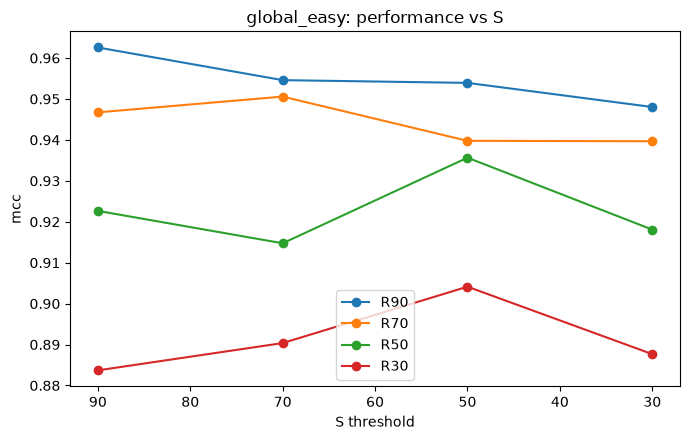

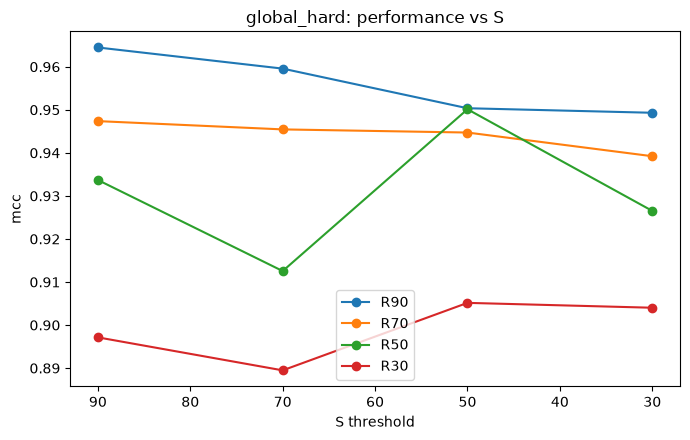

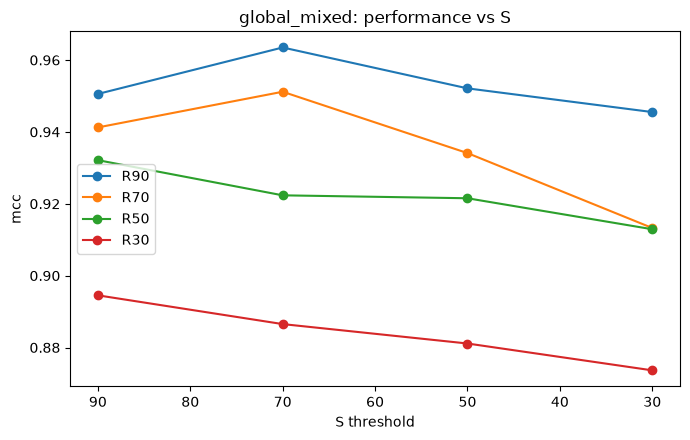

In [13]:
for task in GLOBAL_TASKS:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    g = sub[sub["task"].eq(task)]

    for r in R_LEVELS:
        curve = (
            g[g["R"].eq(r)]
            .set_index("S")
            .reindex(S_LEVELS)
        )
        ax.plot(
            S_LEVELS,
            curve[CURVE_METRIC],
            marker="o",
            label=f"R{r}",
        )

    ax.set_xlabel("S threshold")
    ax.set_ylabel(CURVE_METRIC)
    ax.set_title(f"{task}: performance vs S")
    ax.legend()
    ax.invert_xaxis()
    plt.tight_layout()
    plt.show()

## 8. Task-definition gain curves

Plot the difference between task formulations directly as a function of R or S. This asks whether the effect of task definition itself changes with generalization stringency.

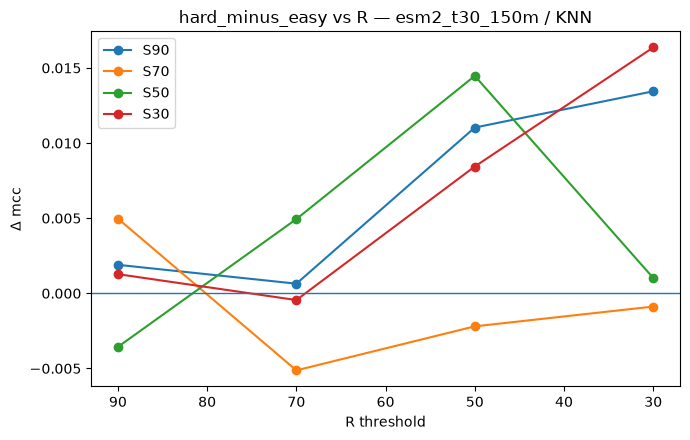

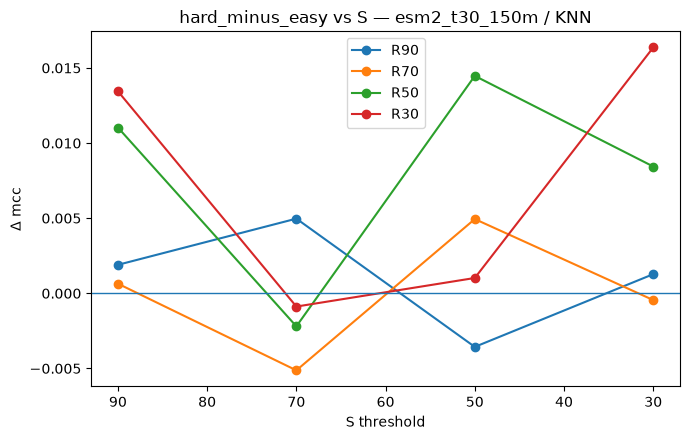

In [14]:
SELECTED_CONTRAST = "hard_minus_easy"
SELECTED_REP = REPRESENTATION
SELECTED_ALG = ALGORITHM

g = negative[
    negative["metric"].eq(metric_to_plot)
    & negative["representation"].eq(SELECTED_REP)
    & negative["algorithm"].eq(SELECTED_ALG)
].copy()

fig, ax = plt.subplots(figsize=(7, 4.5))
for s in S_LEVELS:
    curve = (
        g[g["S"].eq(s)]
        .set_index("R")
        .reindex(R_LEVELS)
    )
    ax.plot(
        R_LEVELS,
        curve[SELECTED_CONTRAST],
        marker="o",
        label=f"S{s}",
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("R threshold")
ax.set_ylabel(f"Δ {metric_to_plot}")
ax.set_title(f"{SELECTED_CONTRAST} vs R — {SELECTED_REP} / {SELECTED_ALG}")
ax.legend()
ax.invert_xaxis()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for r in R_LEVELS:
    curve = (
        g[g["R"].eq(r)]
        .set_index("S")
        .reindex(S_LEVELS)
    )
    ax.plot(
        S_LEVELS,
        curve[SELECTED_CONTRAST],
        marker="o",
        label=f"R{r}",
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("S threshold")
ax.set_ylabel(f"Δ {metric_to_plot}")
ax.set_title(f"{SELECTED_CONTRAST} vs S — {SELECTED_REP} / {SELECTED_ALG}")
ax.legend()
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 9. Does changing the task alter which representation wins?

In [15]:
rank_metric = PRIMARY

rep_rank_rows = []
winner_rows = []

for (r, s, alg), group in global_df.groupby(["R", "S", "algorithm"]):
    piv = group.pivot_table(
        index="representation",
        columns="task",
        values=rank_metric,
        aggfunc="first",
    )

    if not set(GLOBAL_TASKS).issubset(piv.columns):
        continue

    ranks = piv[GLOBAL_TASKS].rank(ascending=False, method="average")

    for ta, tb in [
        ("global_easy", "global_hard"),
        ("global_easy", "global_mixed"),
        ("global_hard", "global_mixed"),
    ]:
        rep_rank_rows.append(
            {
                "R": r,
                "S": s,
                "algorithm": alg,
                "task_A": ta,
                "task_B": tb,
                "spearman_rank_correlation": ranks[ta].corr(ranks[tb], method="spearman"),
            }
        )

    winners = piv[GLOBAL_TASKS].idxmax(axis=0).to_dict()
    winner_rows.append(
        {
            "R": r,
            "S": s,
            "algorithm": alg,
            **{f"winner__{k}": v for k, v in winners.items()},
            "easy_vs_hard_same_winner": winners["global_easy"] == winners["global_hard"],
            "easy_vs_mixed_same_winner": winners["global_easy"] == winners["global_mixed"],
            "hard_vs_mixed_same_winner": winners["global_hard"] == winners["global_mixed"],
        }
    )

rep_rank = pd.DataFrame(rep_rank_rows)
rep_winners = pd.DataFrame(winner_rows)

display(rep_rank.groupby(["task_A", "task_B"])["spearman_rank_correlation"].describe())
display(
    rep_winners[
        [
            "easy_vs_hard_same_winner",
            "easy_vs_mixed_same_winner",
            "hard_vs_mixed_same_winner",
        ]
    ].mean().rename("fraction_same_representation_winner")
)

count      mean       std  min       25%  50%  75%  max
task_A      task_B                                                               
global_easy global_hard    80.0  0.946859  0.093910  0.6  0.911512  1.0  1.0  1.0
            global_mixed   80.0  0.995000  0.031422  0.8  1.000000  1.0  1.0  1.0
global_hard global_mixed   80.0  0.951859  0.085479  0.8  0.987171  1.0  1.0  1.0

easy_vs_hard_same_winner     0.8125
easy_vs_mixed_same_winner    1.0000
hard_vs_mixed_same_winner    0.8125
Name: fraction_same_representation_winner, dtype: float64

## 10. Does changing the task alter which downstream algorithm wins?

In [16]:
alg_rank_rows = []
alg_winner_rows = []

for (r, s, rep), group in global_df.groupby(["R", "S", "representation"]):
    piv = group.pivot_table(
        index="algorithm",
        columns="task",
        values=rank_metric,
        aggfunc="first",
    )

    if not set(GLOBAL_TASKS).issubset(piv.columns):
        continue

    ranks = piv[GLOBAL_TASKS].rank(ascending=False, method="average")

    for ta, tb in [
        ("global_easy", "global_hard"),
        ("global_easy", "global_mixed"),
        ("global_hard", "global_mixed"),
    ]:
        alg_rank_rows.append(
            {
                "R": r,
                "S": s,
                "representation": rep,
                "task_A": ta,
                "task_B": tb,
                "spearman_rank_correlation": ranks[ta].corr(ranks[tb], method="spearman"),
            }
        )

    winners = piv[GLOBAL_TASKS].idxmax(axis=0).to_dict()
    alg_winner_rows.append(
        {
            "R": r,
            "S": s,
            "representation": rep,
            **{f"winner__{k}": v for k, v in winners.items()},
            "easy_vs_hard_same_winner": winners["global_easy"] == winners["global_hard"],
            "easy_vs_mixed_same_winner": winners["global_easy"] == winners["global_mixed"],
            "hard_vs_mixed_same_winner": winners["global_hard"] == winners["global_mixed"],
        }
    )

alg_rank = pd.DataFrame(alg_rank_rows)
alg_winners = pd.DataFrame(alg_winner_rows)

display(alg_rank.groupby(["task_A", "task_B"])["spearman_rank_correlation"].describe())
display(
    alg_winners[
        [
            "easy_vs_hard_same_winner",
            "easy_vs_mixed_same_winner",
            "hard_vs_mixed_same_winner",
        ]
    ].mean().rename("fraction_same_algorithm_winner")
)

count      mean       std       min    25%  50%  75%  max
task_A      task_B                                                                 
global_easy global_hard    64.0  0.175274  0.495024 -0.718185 -0.100  0.2  0.7  1.0
            global_mixed   64.0  0.865625  0.129980  0.600000  0.775  0.9  1.0  1.0
global_hard global_mixed   64.0  0.154241  0.515694 -1.000000 -0.300  0.2  0.6  1.0

easy_vs_hard_same_winner     0.265625
easy_vs_mixed_same_winner    0.734375
hard_vs_mixed_same_winner    0.281250
Name: fraction_same_algorithm_winner, dtype: float64

## 11. How large is the task-definition effect relative to representation and algorithm choice?

This comparison is descriptive:

- representation and algorithm deltas are paired within the same native test cell;
- task-definition deltas generally are not.

The goal is to establish order of magnitude, not formal equivalence of effect sizes.

,count,mean,median,std,min,max
factor,,,,,,
algorithm,1920,0.063450,0.033594,0.080718,0.000000,0.460506
representation,1440,0.215095,0.170699,0.160984,0.000000,0.782917
task_definition,960,0.128268,0.069808,0.140646,0.000073,0.635155


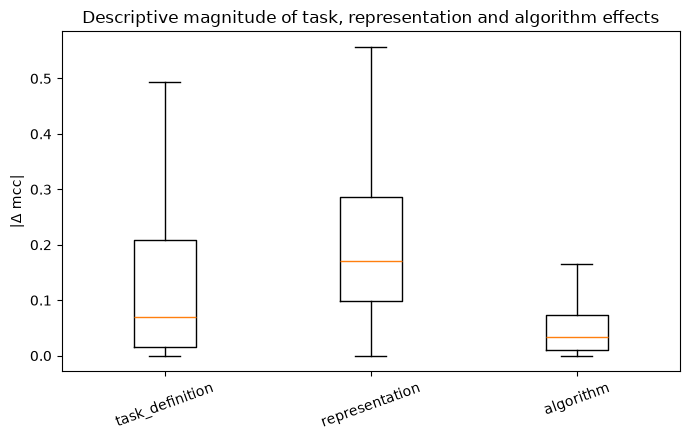

In [17]:
def collect_abs_deltas_for_metric(metric):
    rows = []

    neg = negative[negative["metric"].eq(metric)]
    for c in contrast_cols:
        for value in neg[c].dropna():
            rows.append({"factor": "task_definition", "abs_delta": abs(value), "contrast": c})

    delta_col = f"delta_{metric}_B_minus_A"

    if delta_col in rep_deltas.columns:
        rep_sub = rep_deltas[rep_deltas["task"].isin(GLOBAL_TASKS)]
        for value in rep_sub[delta_col].dropna():
            rows.append({"factor": "representation", "abs_delta": abs(value), "contrast": "pairwise"})

    if delta_col in alg_deltas.columns:
        alg_sub = alg_deltas[alg_deltas["task"].isin(GLOBAL_TASKS)]
        for value in alg_sub[delta_col].dropna():
            rows.append({"factor": "algorithm", "abs_delta": abs(value), "contrast": "pairwise"})

    return pd.DataFrame(rows)

effect_magnitudes = collect_abs_deltas_for_metric(metric_to_plot)

display(
    effect_magnitudes.groupby("factor")["abs_delta"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

fig, ax = plt.subplots(figsize=(7, 4.5))
factors = ["task_definition", "representation", "algorithm"]
data = [
    effect_magnitudes.loc[effect_magnitudes["factor"].eq(f), "abs_delta"].to_numpy()
    for f in factors
]
ax.boxplot(data, tick_labels=factors, showfliers=False)
ax.set_ylabel(f"|Δ {metric_to_plot}|")
ax.set_title("Descriptive magnitude of task, representation and algorithm effects")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 12. Shared-test-entity sensitivity analysis

The cleanest comparisons are:

- `global_easy` vs `global_mixed` on shared outer-test entities;
- `global_hard` vs `global_mixed` on shared outer-test entities.

This cell reads per-sequence predictions and recalculates metrics on the shared subset. Results are cached.

In [18]:
RUN_COMMON_ENTITY_ANALYSIS = True
FORCE_RECOMPUTE_COMMON = False

CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_PATH = CACHE_DIR / "rq1_shared_test_task_definition.tsv"

score_candidates = [
    "score_positive",
    "y_score",
    "y_prob",
    "probability",
    "positive_probability",
]

def detect_score_column(df):
    for c in score_candidates:
        if c in df.columns:
            return c
    raise KeyError(
        f"No positive-score column found. Available columns: {list(df.columns)}"
    )

def recompute_binary_metrics(y_true, score, y_pred=None):
    y_true = np.asarray(y_true).astype(int)
    score = np.asarray(score).astype(float)

    if y_pred is None:
        y_pred = (score >= 0.5).astype(int)
    else:
        y_pred = np.asarray(y_pred).astype(int)

    out = {
        "n": len(y_true),
        "n_positive": int((y_true == 1).sum()),
        "n_negative": int((y_true == 0).sum()),
        "prevalence": float(np.mean(y_true)),
    }

    if len(np.unique(y_true)) < 2:
        out.update({"mcc": np.nan, "ap": np.nan, "balanced_accuracy": np.nan})
        return out

    out["mcc"] = matthews_corrcoef(y_true, y_pred)
    out["ap"] = average_precision_score(y_true, score)
    out["balanced_accuracy"] = balanced_accuracy_score(y_true, y_pred)
    return out

def build_shared_test_analysis():
    exp_paths = expected[["experiment_id", "expected_path"]].copy()
    gmaster = global_df.merge(exp_paths, on="experiment_id", how="left")

    rows = []
    pairs = [
        ("global_easy", "global_mixed"),
        ("global_hard", "global_mixed"),
    ]

    keys = ["R", "S", "representation", "algorithm"]

    for task_a, task_b in pairs:
        a = gmaster[gmaster["task"].eq(task_a)]
        b = gmaster[gmaster["task"].eq(task_b)]

        matched = a.merge(
            b,
            on=keys,
            how="inner",
            suffixes=("_A", "_B"),
        )

        for rec in matched.to_dict("records"):
            path_a = Path(rec["expected_path_A"]) / "outer_test_predictions.parquet"
            path_b = Path(rec["expected_path_B"]) / "outer_test_predictions.parquet"

            pa = pd.read_parquet(path_a)
            pb = pd.read_parquet(path_b)

            score_a = detect_score_column(pa)
            score_b = detect_score_column(pb)

            keep_a = ["entity_id", "y_true", score_a]
            keep_b = ["entity_id", "y_true", score_b]

            if "y_pred" in pa.columns:
                keep_a.append("y_pred")
            if "y_pred" in pb.columns:
                keep_b.append("y_pred")

            pa = pa[keep_a].rename(
                columns={
                    "y_true": "y_true_A",
                    score_a: "score_A",
                    "y_pred": "y_pred_A",
                }
            )

            pb = pb[keep_b].rename(
                columns={
                    "y_true": "y_true_B",
                    score_b: "score_B",
                    "y_pred": "y_pred_B",
                }
            )

            shared = pa.merge(pb, on="entity_id", how="inner")
            shared = shared[
                shared["y_true_A"].eq(shared["y_true_B"])
            ].copy()

            if not len(shared):
                continue

            ma = recompute_binary_metrics(
                shared["y_true_A"],
                shared["score_A"],
                shared["y_pred_A"] if "y_pred_A" in shared.columns else None,
            )
            mb = recompute_binary_metrics(
                shared["y_true_B"],
                shared["score_B"],
                shared["y_pred_B"] if "y_pred_B" in shared.columns else None,
            )

            row = {
                **{k: rec[k] for k in keys},
                "task_A": task_a,
                "task_B": task_b,
                "n_shared": len(shared),
                "n_shared_positive": ma["n_positive"],
                "n_shared_negative": ma["n_negative"],
                "shared_prevalence": ma["prevalence"],
            }

            for metric in ["mcc", "ap", "balanced_accuracy"]:
                row[f"{metric}_A"] = ma[metric]
                row[f"{metric}_B"] = mb[metric]
                row[f"delta_{metric}_B_minus_A"] = (
                    mb[metric] - ma[metric]
                    if pd.notna(ma[metric]) and pd.notna(mb[metric])
                    else np.nan
                )

            rows.append(row)

    return pd.DataFrame(rows)

if RUN_COMMON_ENTITY_ANALYSIS:
    if CACHE_PATH.is_file() and not FORCE_RECOMPUTE_COMMON:
        common = pd.read_csv(CACHE_PATH, sep="\t", low_memory=False)
        print("Loaded cache:", CACHE_PATH)
    else:
        common = build_shared_test_analysis()
        common.to_csv(CACHE_PATH, sep="\t", index=False)
        print("Wrote cache:", CACHE_PATH)

    display(common.head())

    print("\nShared support:")
    display(
        common.groupby(["task_A", "task_B"])[
            ["n_shared", "n_shared_positive", "n_shared_negative"]
        ].describe()
    )

    print("\nShared-test paired deltas:")
    delta_cols = [
        c for c in common.columns
        if c.startswith("delta_") and c.endswith("_B_minus_A")
    ]
    display(
        common.groupby(["task_A", "task_B"])[delta_cols]
        .agg(["mean", "median", "std", "min", "max"])
    )

Wrote cache: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq1_shared_test_task_definition.tsv


,R,S,representation,algorithm,task_A,task_B,n_shared,n_shared_positive,n_shared_negative,shared_prevalence,mcc_A,mcc_B,delta_mcc_B_minus_A,ap_A,ap_B,delta_ap_B_minus_A,balanced_accuracy_A,balanced_accuracy_B,delta_balanced_accuracy_B_minus_A
0,90,90,roxy_48,LR,global_easy,global_mixed,2748,486,2262,0.176856,0.527453,0.542182,0.014728,0.643894,0.653553,0.009659,0.815819,0.821566,0.005747
1,90,90,roxy_48,RF,global_easy,global_mixed,2748,486,2262,0.176856,0.677540,0.694009,0.016469,0.859498,0.858020,-0.001477,0.783637,0.791723,0.008086
2,90,90,roxy_48,KNN,global_easy,global_mixed,2748,486,2262,0.176856,0.779211,0.773887,-0.005324,0.843870,0.851349,0.007479,0.864904,0.856164,-0.008741
3,90,90,roxy_48,XGB,global_easy,global_mixed,2748,486,2262,0.176856,0.759223,0.769506,0.010283,0.885616,0.893140,0.007524,0.873994,0.876792,0.002797
4,90,90,roxy_48,MLP,global_easy,global_mixed,2748,486,2262,0.176856,0.772575,0.773760,0.001186,0.882800,0.883852,0.001052,0.881859,0.855356,-0.026503



Shared support:


n_shared                                                                 n_shared_positive                                                            \
                            count       mean         std    min      25%     50%      75%     max             count      mean         std    min    25%    50%     75%    max   
task_A      task_B                                                                                                                                                              
global_easy global_mixed    320.0  1742.3125  719.817873  797.0  1262.00  1623.5  2202.75  2872.0             320.0  314.0625  117.117666  144.0  203.0  327.5  389.00  486.0   
global_hard global_mixed    320.0   396.6875  139.533805  216.0   296.25   375.0   467.50   647.0             320.0  282.0625  109.427962  145.0  201.0  263.0  352.75  495.0   

                         n_shared_negative                                                               
                                     count      mean         std    min     25%     50%     75%     max  
task_A      task_B                                                                                       
global_easy global_mixed             320.0  1428.250  619.954847  652.0  974.25  1318.5  1839.0  2387.0  
global_hard global_mixed             320.0   114.625   33.041961   71.0   91.25   110.0   131.0   186.0


Shared-test paired deltas:


delta_mcc_B_minus_A                                         delta_ap_B_minus_A                                         delta_balanced_accuracy_B_minus_A  \
                                        mean    median       std       min       max               mean    median       std       min       max                              mean   
task_A      task_B                                                                                                                                                                  
global_easy global_mixed           -0.005479 -0.003874  0.021990 -0.100658  0.069781          -0.002285 -0.002213  0.019676 -0.097783  0.079170                         -0.004199   
global_hard global_mixed           -0.245211 -0.229062  0.144131 -0.731193 -0.027348          -0.026800 -0.013617  0.029900 -0.138387  0.004079                         -0.109455   

                                                                  
                            median       std       min       max  
task_A      task_B                                                
global_easy global_mixed -0.004090  0.012514 -0.060905  0.036417  
global_hard global_mixed -0.094211  0.085355 -0.411982  0.006487

## 13. Native-test versus shared-test conclusions

If the direction of the task-definition effect is preserved on shared entities, the claim is much stronger.

In [19]:
if RUN_COMMON_ENTITY_ANALYSIS and "common" in globals() and len(common):
    native_mcc = negative[negative["metric"].eq("mcc")].copy() if "mcc" in negative["metric"].unique() else None

    if native_mcc is not None:
        rows = []

        shared_em = common[
            common["task_A"].eq("global_easy")
            & common["task_B"].eq("global_mixed")
        ]["delta_mcc_B_minus_A"].dropna()

        native_em = native_mcc["mixed_minus_easy"].dropna()

        rows.append({
            "comparison": "mixed_minus_easy",
            "native_median_delta": native_em.median(),
            "native_fraction_positive": (native_em > 0).mean(),
            "shared_median_delta": shared_em.median(),
            "shared_fraction_positive": (shared_em > 0).mean(),
            "n_shared_comparisons": len(shared_em),
        })

        shared_hm = common[
            common["task_A"].eq("global_hard")
            & common["task_B"].eq("global_mixed")
        ]["delta_mcc_B_minus_A"].dropna()

        native_hm = (-native_mcc["hard_minus_mixed"]).dropna()

        rows.append({
            "comparison": "mixed_minus_hard",
            "native_median_delta": native_hm.median(),
            "native_fraction_positive": (native_hm > 0).mean(),
            "shared_median_delta": shared_hm.median(),
            "shared_fraction_positive": (shared_hm > 0).mean(),
            "n_shared_comparisons": len(shared_hm),
        })

        display(pd.DataFrame(rows))

,comparison,native_median_delta,native_fraction_positive,shared_median_delta,shared_fraction_positive,n_shared_comparisons
0,mixed_minus_easy,-0.004137,0.409375,-0.003874,0.346875,320
1,mixed_minus_hard,-0.167108,0.028125,-0.229062,0.000000,320


# 14. RQ1 synthesis

Use this final section to decide what the actual Result is.

### Questions to answer after execution

1. Which task definition has the highest/lowest apparent performance?
2. How much of the AP difference is explained by prevalence?
3. Is the direction of `hard−easy`, `mixed−easy`, and `hard−mixed` consistent across the factorial?
4. Does the task-definition effect change with R or S?
5. Does changing the task alter representation rankings?
6. Does changing the task alter algorithm rankings?
7. Is the magnitude of task-definition change comparable to or larger than model-choice effects?
8. Do shared-test entities support the same directional conclusion?
9. Should `easy/hard` be replaced by semantic names in the manuscript?
10. What general lesson about protein-function prediction follows from this case study?

In [20]:
rq1_rows = []

for metric in [m for m in ["mcc", "ap", "ap_gain"] if m in negative["metric"].unique()]:
    sub = negative[negative["metric"].eq(metric)]

    for contrast in contrast_cols:
        x = sub[contrast].dropna()
        rq1_rows.append(
            {
                "evidence": "native_task_contrast",
                "metric": metric,
                "contrast": contrast,
                "median_delta": x.median(),
                "mean_delta": x.mean(),
                "fraction_positive": (x > 0).mean(),
                "fraction_negative": (x < 0).mean(),
                "n": len(x),
            }
        )

rq1_evidence = pd.DataFrame(rq1_rows)
display(rq1_evidence)

print("\nRepresentation winner stability:")
display(
    rep_winners[
        [
            "easy_vs_hard_same_winner",
            "easy_vs_mixed_same_winner",
            "hard_vs_mixed_same_winner",
        ]
    ].mean().to_frame("fraction_same_winner")
)

print("\nAlgorithm winner stability:")
display(
    alg_winners[
        [
            "easy_vs_hard_same_winner",
            "easy_vs_mixed_same_winner",
            "hard_vs_mixed_same_winner",
        ]
    ].mean().to_frame("fraction_same_winner")
)

if RUN_COMMON_ENTITY_ANALYSIS and "common" in globals() and len(common):
    print("\nShared-test task contrasts:")
    available = [
        c for c in [
            "delta_mcc_B_minus_A",
            "delta_ap_B_minus_A",
            "delta_balanced_accuracy_B_minus_A",
        ]
        if c in common.columns
    ]
    display(
        common.groupby(["task_A", "task_B"])[available]
        .agg(["mean", "median", "std", "min", "max"])
    )

,evidence,metric,contrast,median_delta,mean_delta,fraction_positive,fraction_negative,n
0,native_task_contrast,mcc,hard_minus_easy,0.169034,0.182114,0.965625,0.034375,320
1,native_task_contrast,mcc,mixed_minus_easy,-0.004137,-0.004264,0.409375,0.590625,320
2,native_task_contrast,mcc,hard_minus_mixed,0.167108,0.186378,0.971875,0.028125,320
3,native_task_contrast,ap,hard_minus_easy,0.136168,0.190543,1.000000,0.000000,320
4,native_task_contrast,ap,mixed_minus_easy,-0.005953,-0.007938,0.296875,0.703125,320
5,native_task_contrast,ap,hard_minus_mixed,0.144119,0.198481,1.000000,0.000000,320
6,native_task_contrast,ap_gain,hard_minus_easy,-0.375947,-0.335836,0.018750,0.981250,320
7,native_task_contrast,ap_gain,mixed_minus_easy,0.007465,0.007620,0.706250,0.293750,320
8,native_task_contrast,ap_gain,hard_minus_mixed,-0.387181,-0.343456,0.006250,0.993750,320



Representation winner stability:


,fraction_same_winner
easy_vs_hard_same_winner,0.8125
easy_vs_mixed_same_winner,1.0000
hard_vs_mixed_same_winner,0.8125



Algorithm winner stability:


,fraction_same_winner
easy_vs_hard_same_winner,0.265625
easy_vs_mixed_same_winner,0.734375
hard_vs_mixed_same_winner,0.281250



Shared-test task contrasts:


delta_mcc_B_minus_A                                         delta_ap_B_minus_A                                         delta_balanced_accuracy_B_minus_A  \
                                        mean    median       std       min       max               mean    median       std       min       max                              mean   
task_A      task_B                                                                                                                                                                  
global_easy global_mixed           -0.005479 -0.003874  0.021990 -0.100658  0.069781          -0.002285 -0.002213  0.019676 -0.097783  0.079170                         -0.004199   
global_hard global_mixed           -0.245211 -0.229062  0.144131 -0.731193 -0.027348          -0.026800 -0.013617  0.029900 -0.138387  0.004079                         -0.109455   

                                                                  
                            median       std       min       max  
task_A      task_B                                                
global_easy global_mixed -0.004090  0.012514 -0.060905  0.036417  
global_hard global_mixed -0.094211  0.085355 -0.411982  0.006487

## What this notebook should not conclude

Do not conclude that one negative class is biologically “easy” or “hard” solely from a higher MCC/AP.

The strongest defensible conclusion is about task formulation:

> changing what counts as the comparison/background class can materially alter the apparent learnability, ranking and generalization behavior of the same biological positive concept.

Whether the data support that statement strongly enough for the *Briefings* narrative is what this notebook is designed to determine.